In [33]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from numba import njit

from joblib import Parallel, delayed

In [34]:
@njit(cache=True, fastmath=True)
def solve_core(nx, ny, C0, k, mask_u8, tol, max_iter, omega):
    C = np.full((nx, ny), C0)
    # enforce top boundary (Dirichlet)
    for x in range(nx):
        C[x, ny - 1] = C0

    for it in range(1, max_iter + 1):
        max_change = 0.0

        # sweep all rows except the top (Dirichlet)
        for y in range(ny - 1):
            for x in range(nx):
                # left/right neighbors with Neumann mirrors
                if x == 0:
                    left = C[1, y]
                else:
                    left = C[x - 1, y]

                if x == nx - 1:
                    right = C[nx - 2, y]
                else:
                    right = C[x + 1, y]

                top = C[x, y + 1]  # valid since y <= ny-2

                if y == 0:
                    # bottom boundary
                    if mask_u8[x] == 1:
                        # zero-flux: ghost = C[x,1]
                        numer = left + right + top + C[x, 1]
                        denom = 4.0
                        newC = numer / denom
                    else:
                        # Robin dC/dy = k*C  ->  C0 = (left+right+top+C1)/(4+2k)
                        numer = left + right + top + C[x, 1]
                        denom = 4.0 + 2.0 * k  # dy=1
                        newC = numer / denom
                else:
                    bottom = C[x, y - 1]
                    newC = 0.25 * (left + right + top + bottom)

                old = C[x, y]
                Cxy = (1.0 - omega) * old + omega * newC
                C[x, y] = Cxy

                diff = Cxy - old
                if diff < 0.0:
                    diff = -diff
                if diff > max_change:
                    max_change = diff

        # re-enforce top boundary explicitly (keeps round-off in check)
        for x in range(nx):
            C[x, ny - 1] = C0

        for y in range(ny):
            #C[0, y] = C0
            a=1

        if max_change < tol:
            print("converged")
            return C, it, max_change

    return C, max_iter, max_change

nx_ratio =  1000.0


(-0.1, 1.1)

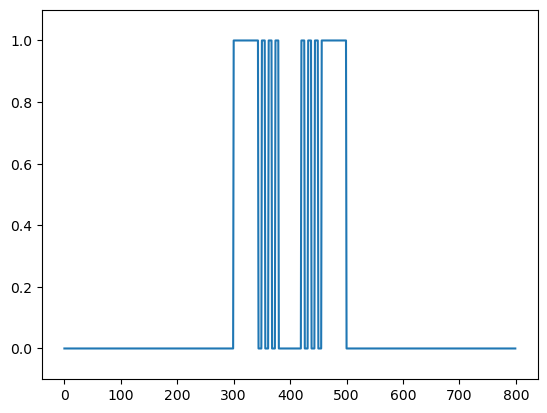

In [35]:
nx = 800
ny = 400
k = 1/1000          # absorption strength (per grid cell)

L_grid = 0.5 # 100 um for 200 grid
#L_grid = 100
nx_ratio = 500/0.5
print('nx_ratio = ',nx_ratio)

L_gap = int(20//L_grid)
L_mask1 = int(3//L_grid)
L_mask2 = int(3//L_grid)
L_mask_side = int(40//L_grid-3*(L_mask1+L_mask2))

non_absorb_mask = np.zeros(nx)
non_absorb_mask[nx//2+L_gap//2 : nx//2+L_gap//2+L_mask1] = True
non_absorb_mask[nx//2+L_gap//2+L_mask1+L_mask2 : nx//2+L_gap//2+2*L_mask1+L_mask2] = True
non_absorb_mask[nx//2+L_gap//2+2*L_mask1+2*L_mask2 : nx//2+L_gap//2+3*L_mask1+2*L_mask2] = True
non_absorb_mask[nx//2+L_gap//2+3*L_mask1+3*L_mask2 : nx//2+L_gap//2+3*L_mask1+3*L_mask2+L_mask_side] = True

non_absorb_mask[0: nx//2] = non_absorb_mask[nx//2:][::-1]

plt.plot(non_absorb_mask)
plt.ylim([-0.1, 1.1])

In [21]:
C0 = 1.0         # top concentration

C, iters, maxchange = solve_core(nx, ny, C0, k, non_absorb_mask, tol=1e-7, max_iter=500000, omega=1.2)
print(f"Solved in {iters} iterations. Array shape: {C.shape}")
print(f"Max change: {maxchange}")

converged
Solved in 230863 iterations. Array shape: (800, 400)
Max change: 9.999903158863787e-08


In [36]:
np.save("diffusion_result", C)

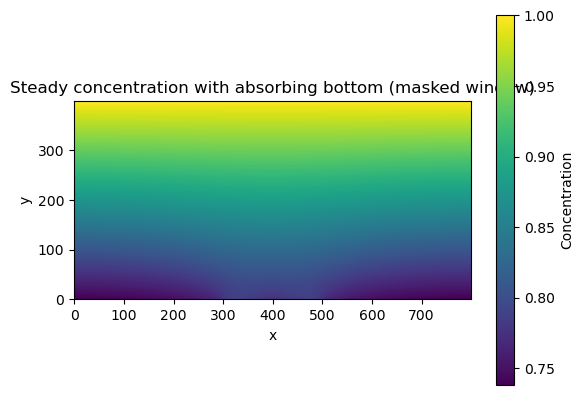

In [22]:

plt.imshow(C.T, origin="lower", aspect="1")
plt.colorbar(label="Concentration")
plt.title("Steady concentration with absorbing bottom (masked window)")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

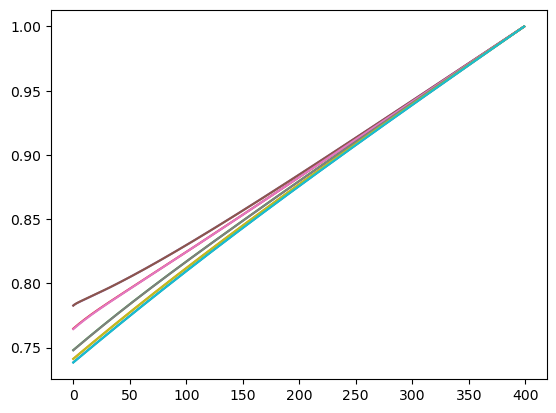

In [23]:
for i in range(10):
    plt.plot(C[i*(nx//10)+nx//20, :], label = f'{i*(nx//10)+nx//20}')

In [24]:
slope = (C[nx//2, 5]-C[nx//2, 0])/5
b1_measured = C[nx//2, 0]/slope
print(b1_measured)

1045.6186927129525


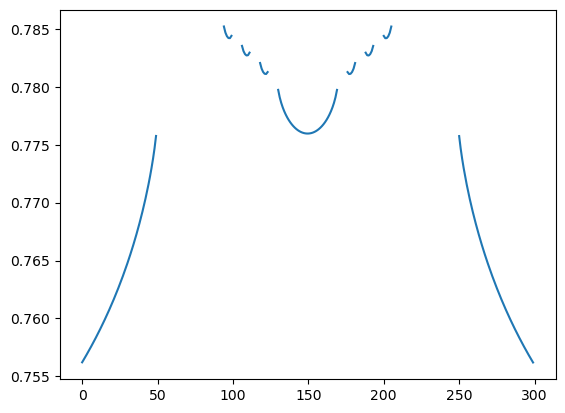

In [25]:
range_plot = slice(250,550)

boundary_concentration = C[:, 0]
boundary_concentration[non_absorb_mask==1] = np.nan

plt.plot(C[range_plot, 0])
#plt.ylim(bottom=0)

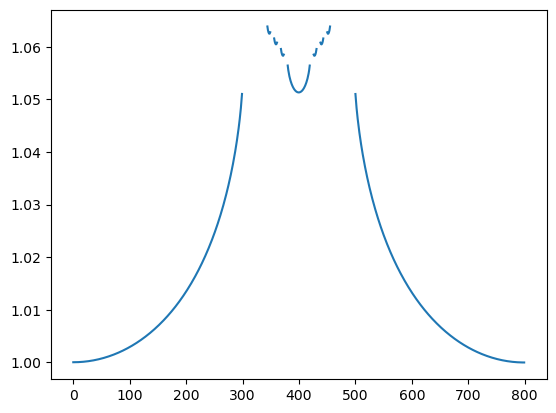

In [32]:
base_concentration = np.nanmin(boundary_concentration)
percentage = boundary_concentration/base_concentration

plt.plot(percentage)